<a href="https://colab.research.google.com/github/Diksha-Lakhani/Cement_analysis/blob/main/cement_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# import gdown
import joblib, os
from google.colab import drive

# url = 'https://drive.google.com/file/d/18l2VupzssZKWs885-pGvzr-XVcuUrDhv/view?usp=sharing'
# gdown.download(url, 'Concrete_Data.csv', quiet=False, fuzzy=True)

try:
    from google.colab import drive
    drive.mount('/content/drive')
    save_dir = "/content/drive/MyDrive/cement_analysis"
except ImportError:
    save_dir = "models"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Importing dataset

In [51]:
df = pd.read_csv('Concrete_Data.csv')

In [52]:
df.head(5)

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [53]:
df.shape

(1030, 9)

In [54]:
df.columns = ["cement", "slag", "fly_ash", "water", "superplasticizer","coarse_agg", "fine_agg", "age", "strength"]

## Checking null values

In [55]:
df.isnull().sum()

,0
cement,0
slag,0
fly_ash,0
water,0
superplasticizer,0
coarse_agg,0
fine_agg,0
age,0
strength,0


## Checking and cleaning duplicate values

In [56]:
df[df.duplicated()]

,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,strength
77,425.0,106.3,0.0,153.5,16.5,852.1,887.1,3,33.40
80,425.0,106.3,0.0,153.5,16.5,852.1,887.1,3,33.40
86,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.30
88,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.30
91,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.30
100,425.0,106.3,0.0,153.5,16.5,852.1,887.1,7,49.20
103,425.0,106.3,0.0,153.5,16.5,852.1,887.1,7,49.20
109,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.90
111,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.90
123,425.0,106.3,0.0,153.5,16.5,852.1,887.1,28,60.29


In [57]:
df.drop_duplicates(keep="first",inplace=True)

In [58]:
df.duplicated().sum()
df.shape

(1005, 9)

In [59]:
df=df.reset_index(drop=True)

## Checking outliers

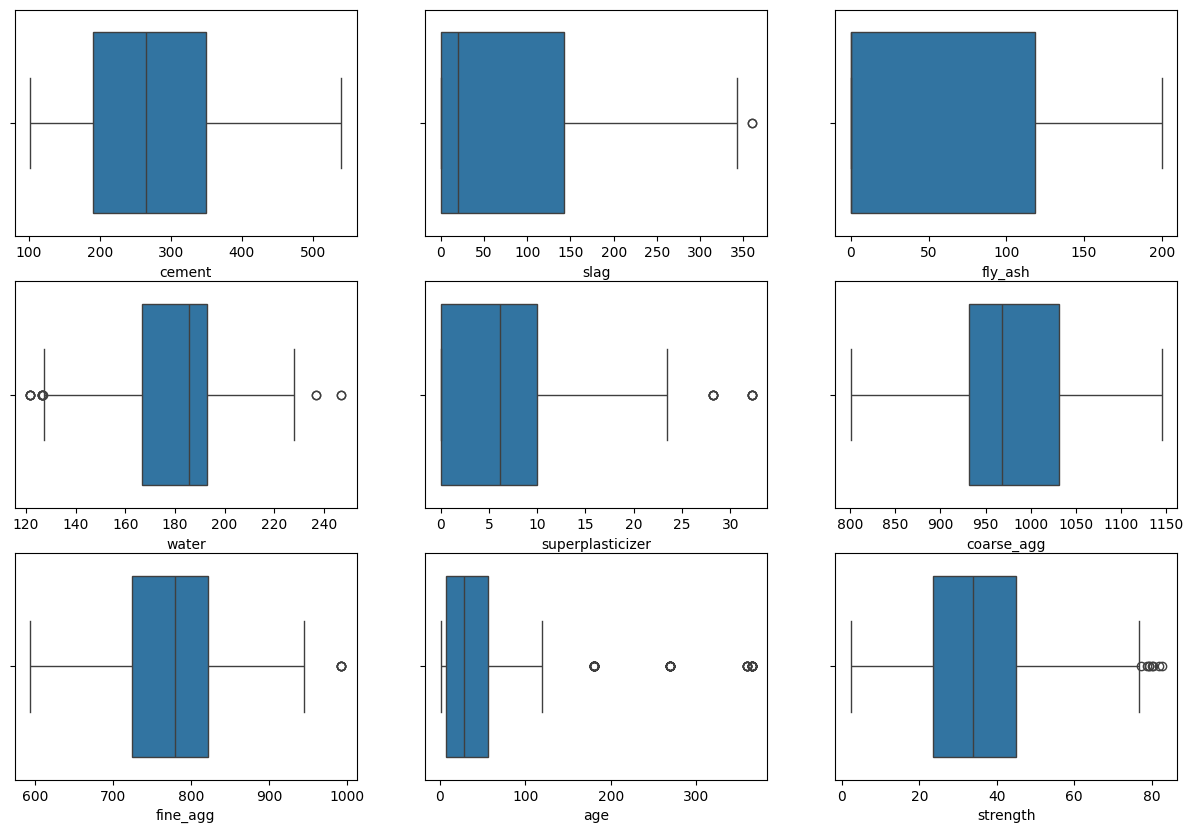

In [60]:
plt.figure(figsize=(15,10))
plotnum = 1

for i in df.columns:
  if plotnum <= 9:
    ax = plt.subplot(3,3,plotnum)
    sns.boxplot(data=df, x=i, ax=ax)
    # plt.title(f"{i}")
  plotnum+=1

plt.savefig(f"{save_dir}/before_boxplot.png", dpi=150, bbox_inches="tight")
plt.show()

The columns that have major outliers in them are water, superplasticizer and age. As the data in the outliers are important, we will not be removing the outliers outright.


## Exploratory Data Analysis (EDA)

1) Univariate analysis

In [61]:
df.describe()

,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,strength
count,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000
mean,278.631343,72.043483,55.536318,182.075323,6.033234,974.376816,772.688259,45.856716,35.250378
std,104.344261,86.170807,64.207969,21.339334,5.919967,77.579667,80.340435,63.734692,16.284815
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,594.000000,1.000000,2.330000
25%,190.700000,0.000000,0.000000,166.600000,0.000000,932.000000,724.300000,7.000000,23.520000
50%,265.000000,20.000000,0.000000,185.700000,6.100000,968.000000,780.000000,28.000000,33.800000
75%,349.000000,142.500000,118.300000,192.900000,10.000000,1031.000000,822.200000,56.000000,44.870000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000


In [62]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1005 entries, 0 to 1004
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   cement            1005 non-null   float64
 1   slag              1005 non-null   float64
 2   fly_ash           1005 non-null   float64
 3   water             1005 non-null   float64
 4   superplasticizer  1005 non-null   float64
 5   coarse_agg        1005 non-null   float64
 6   fine_agg          1005 non-null   float64
 7   age               1005 non-null   int64  
 8   strength          1005 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 70.8 KB


As all of the columns have numeric data, we dont have to encode the data

/tmp/ipykernel_1095/1229733579.py:7: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df[col])
/tmp/ipykernel_1095/1229733579.py:7: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df[col])
/tmp/ipykernel_1095/1229733579.py:7: UserWarning: 

`distplot` is a deprecated function and will be removed in s

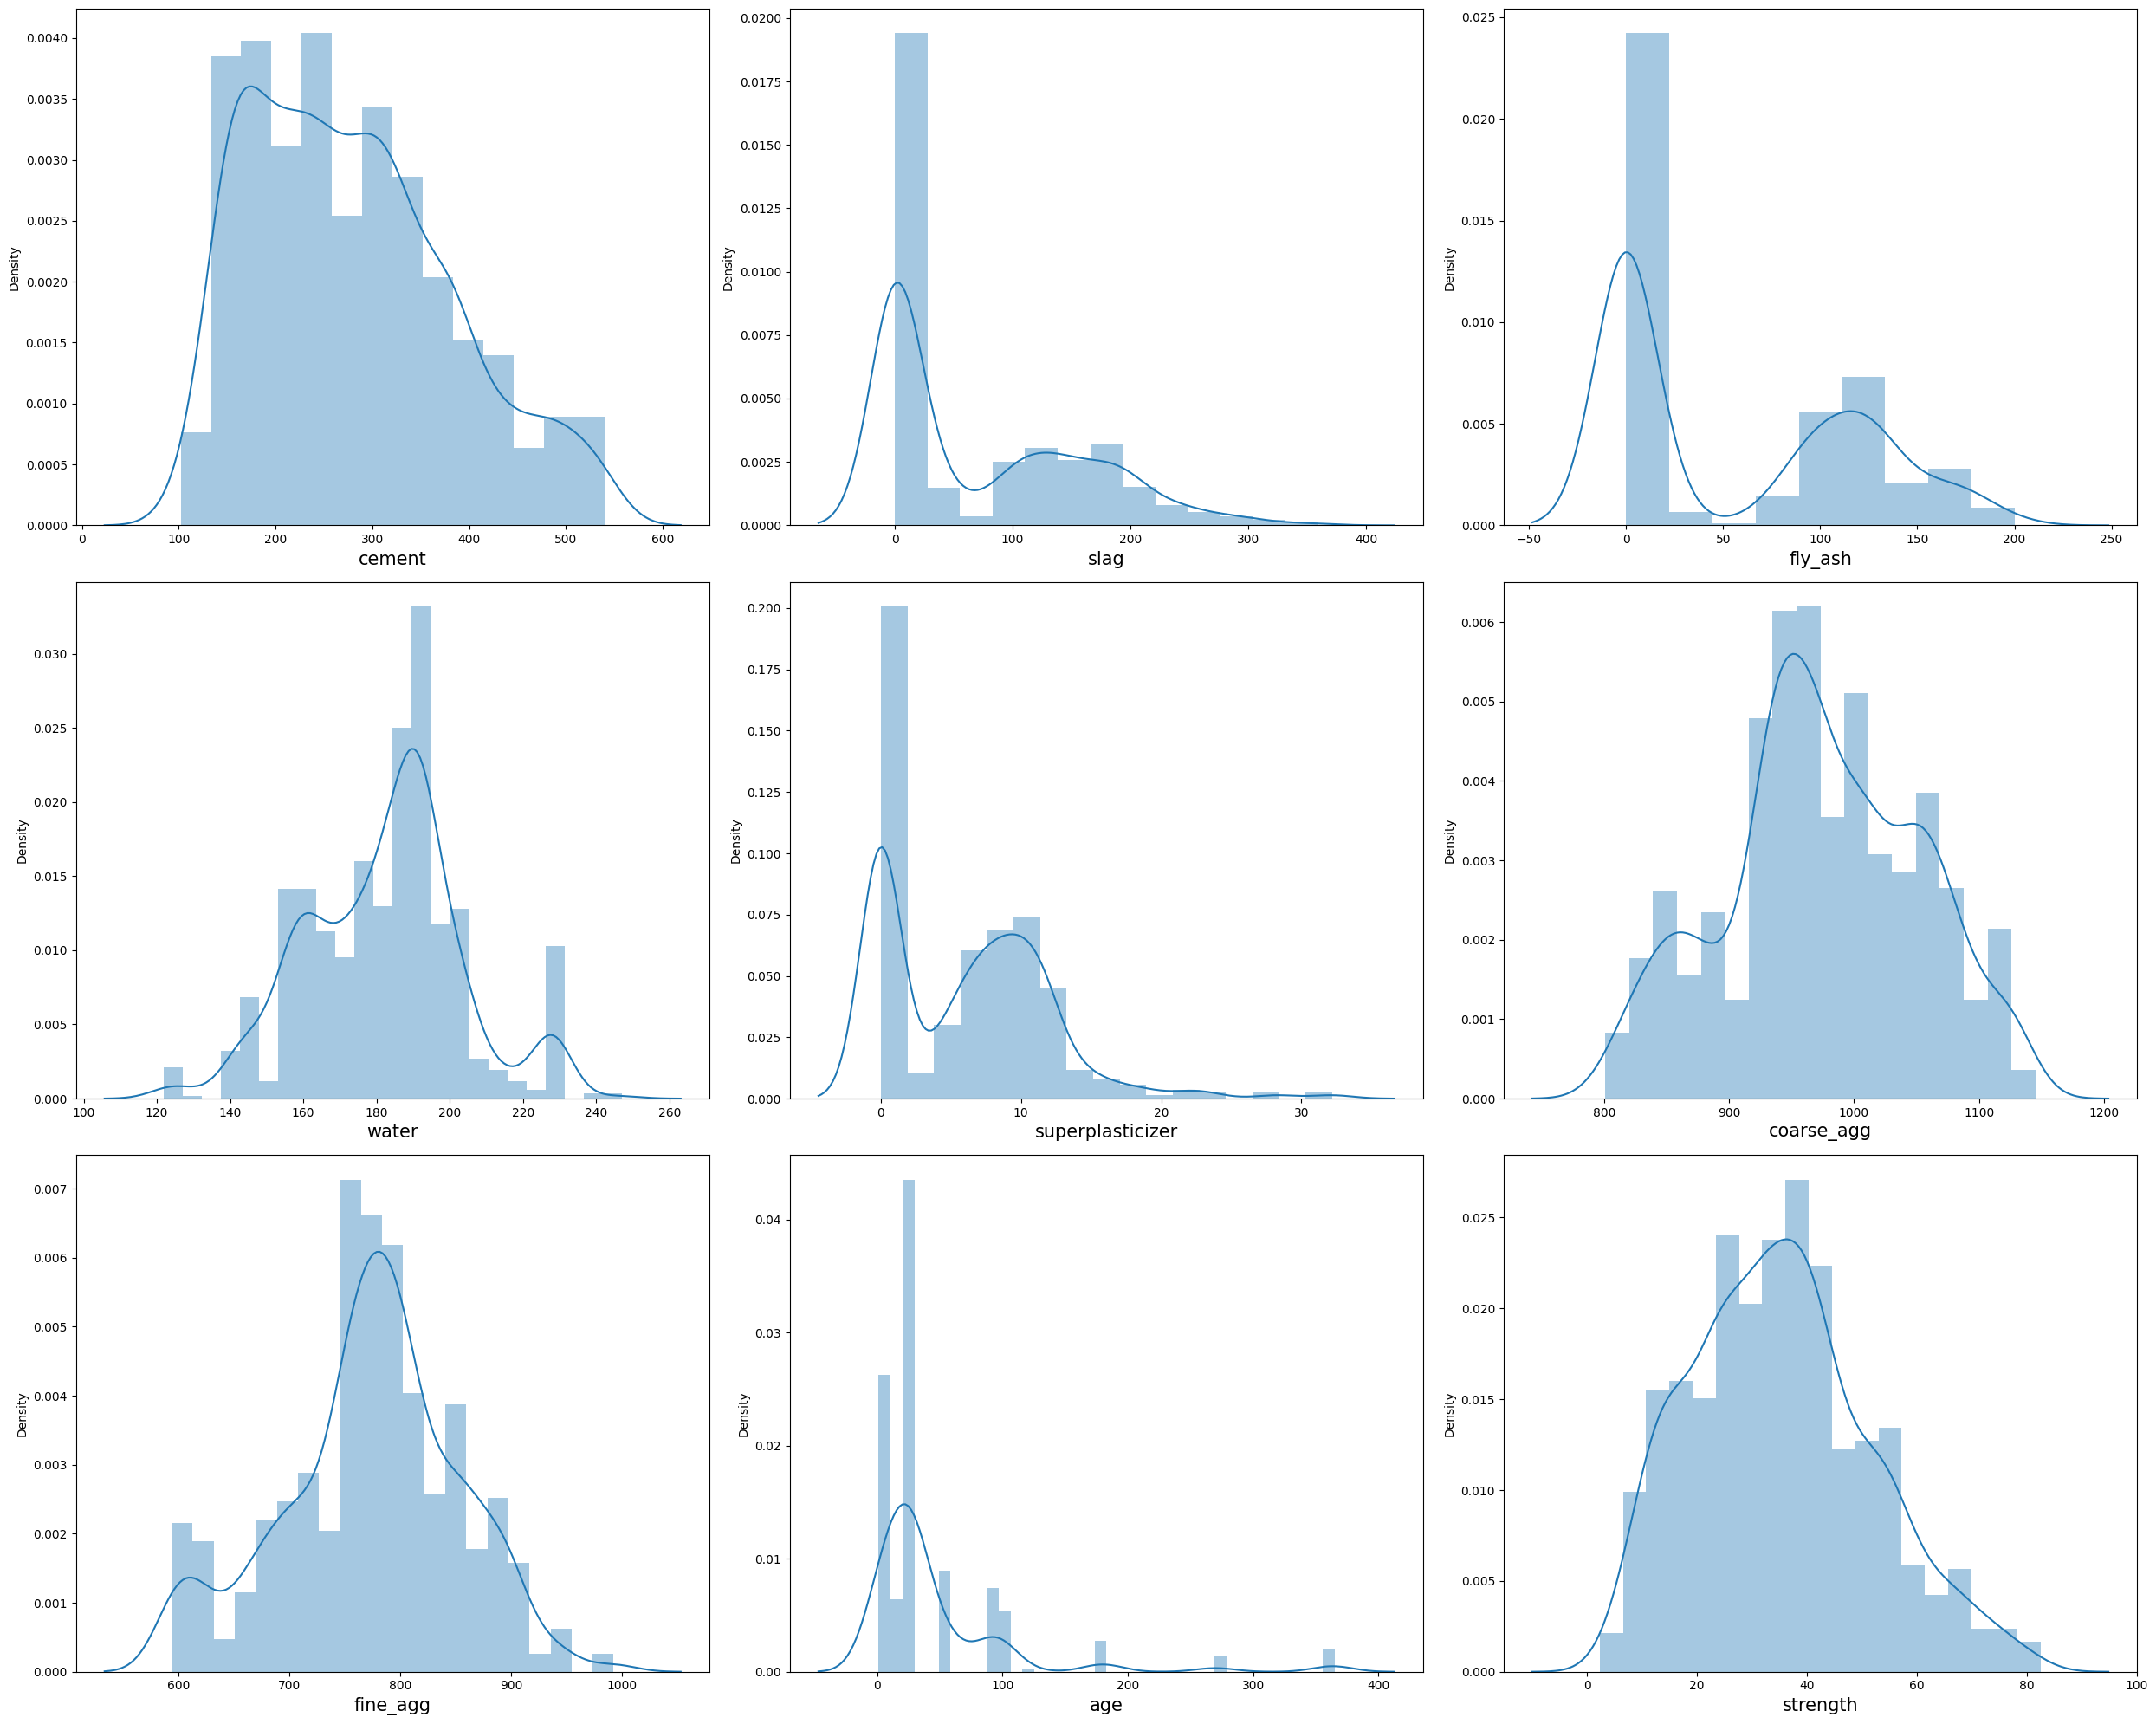

In [63]:
plt.figure(figsize = (25, 20))
plotnumber = 1

for col in df.columns:
    if plotnumber <= 9:
        ax = plt.subplot(3, 3, plotnumber)
        sns.distplot(df[col])
        plt.xlabel(col, fontsize = 15)

    plotnumber += 1

plt.tight_layout()
plt.show()

In [64]:
df.skew()

,0
cement,0.564959
slag,0.855225
fly_ash,0.497231
water,0.034433
superplasticizer,0.980604
coarse_agg,-0.065256
fine_agg,-0.252353
age,3.253974
strength,0.395696


We can see from both the normal graph and skew function that the columns of slag, superplasticiser, age are skewed

## 2. Bivariate analysis

In [65]:
input = df.iloc[:,:-1]
output = df.iloc[:,-1]

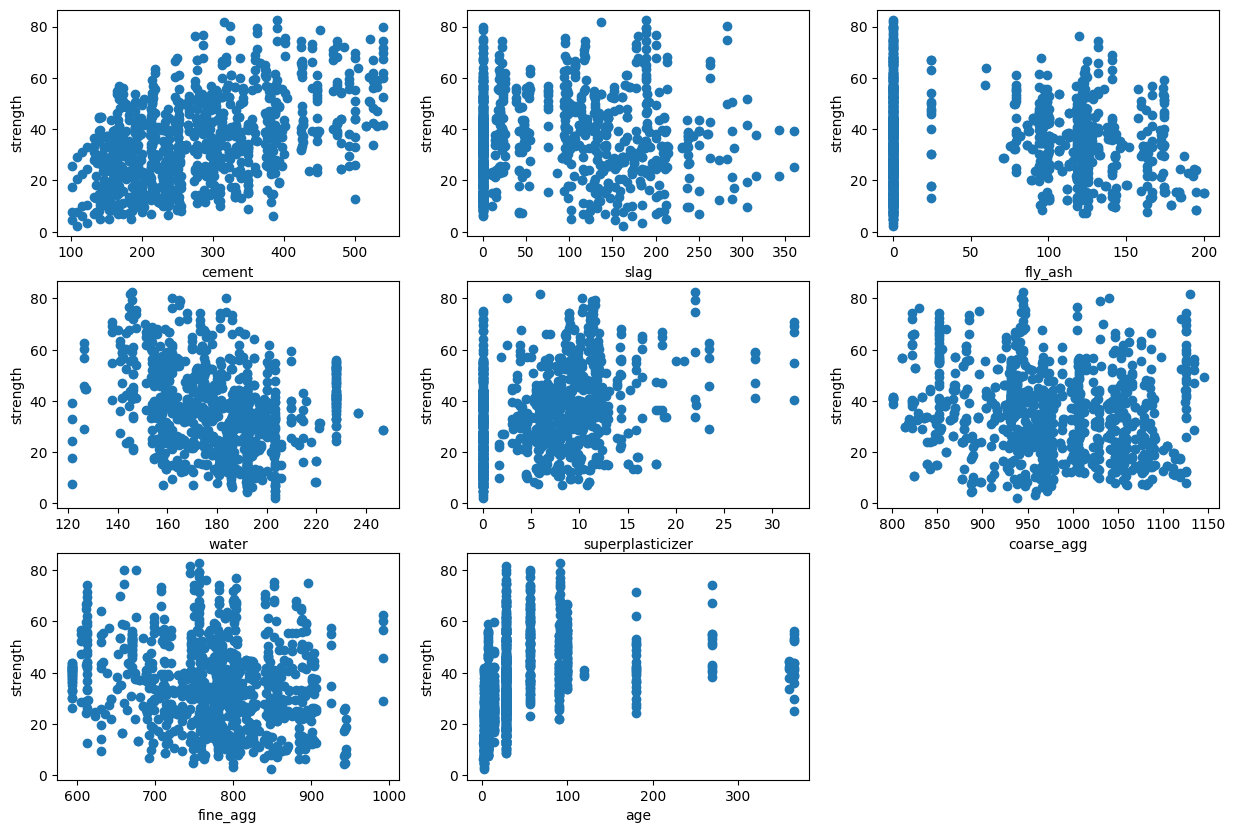

In [66]:
plt.figure(figsize=(15,10))
plotnum=1

for i in input.columns:
  if plotnum<=9:
    plt.subplot(3,3,plotnum)
    plt.scatter(input[i],output)
    plt.xlabel(i)
    plt.ylabel(output.name)
  plotnum+=1
plt.show()

Major insights
1. Strength and cement have an upward trend with a wide scatter. This shows that an increase in cement will increase the strength.
2. Strength and water have an downward trend which means less water is needed to increase.
3. The age feature rises steeply then flattens and is curved rather than linear. The points are in vertical stripes because we have taken only a few distinct values of aging.
4. Superplasticize, slag, fly_ash have bif stacks of 0 but this is not an outlier or an error.

## 3. correlation

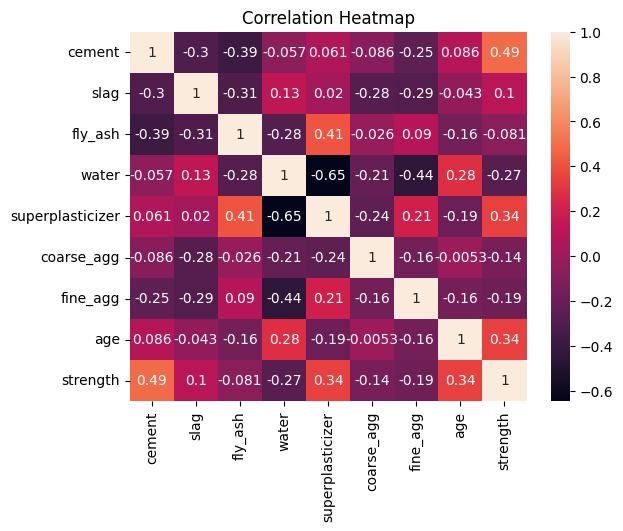

In [67]:
sns.heatmap(df.corr(), annot=True)
plt.title("Correlation Heatmap")
plt.savefig(f"{save_dir}/correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

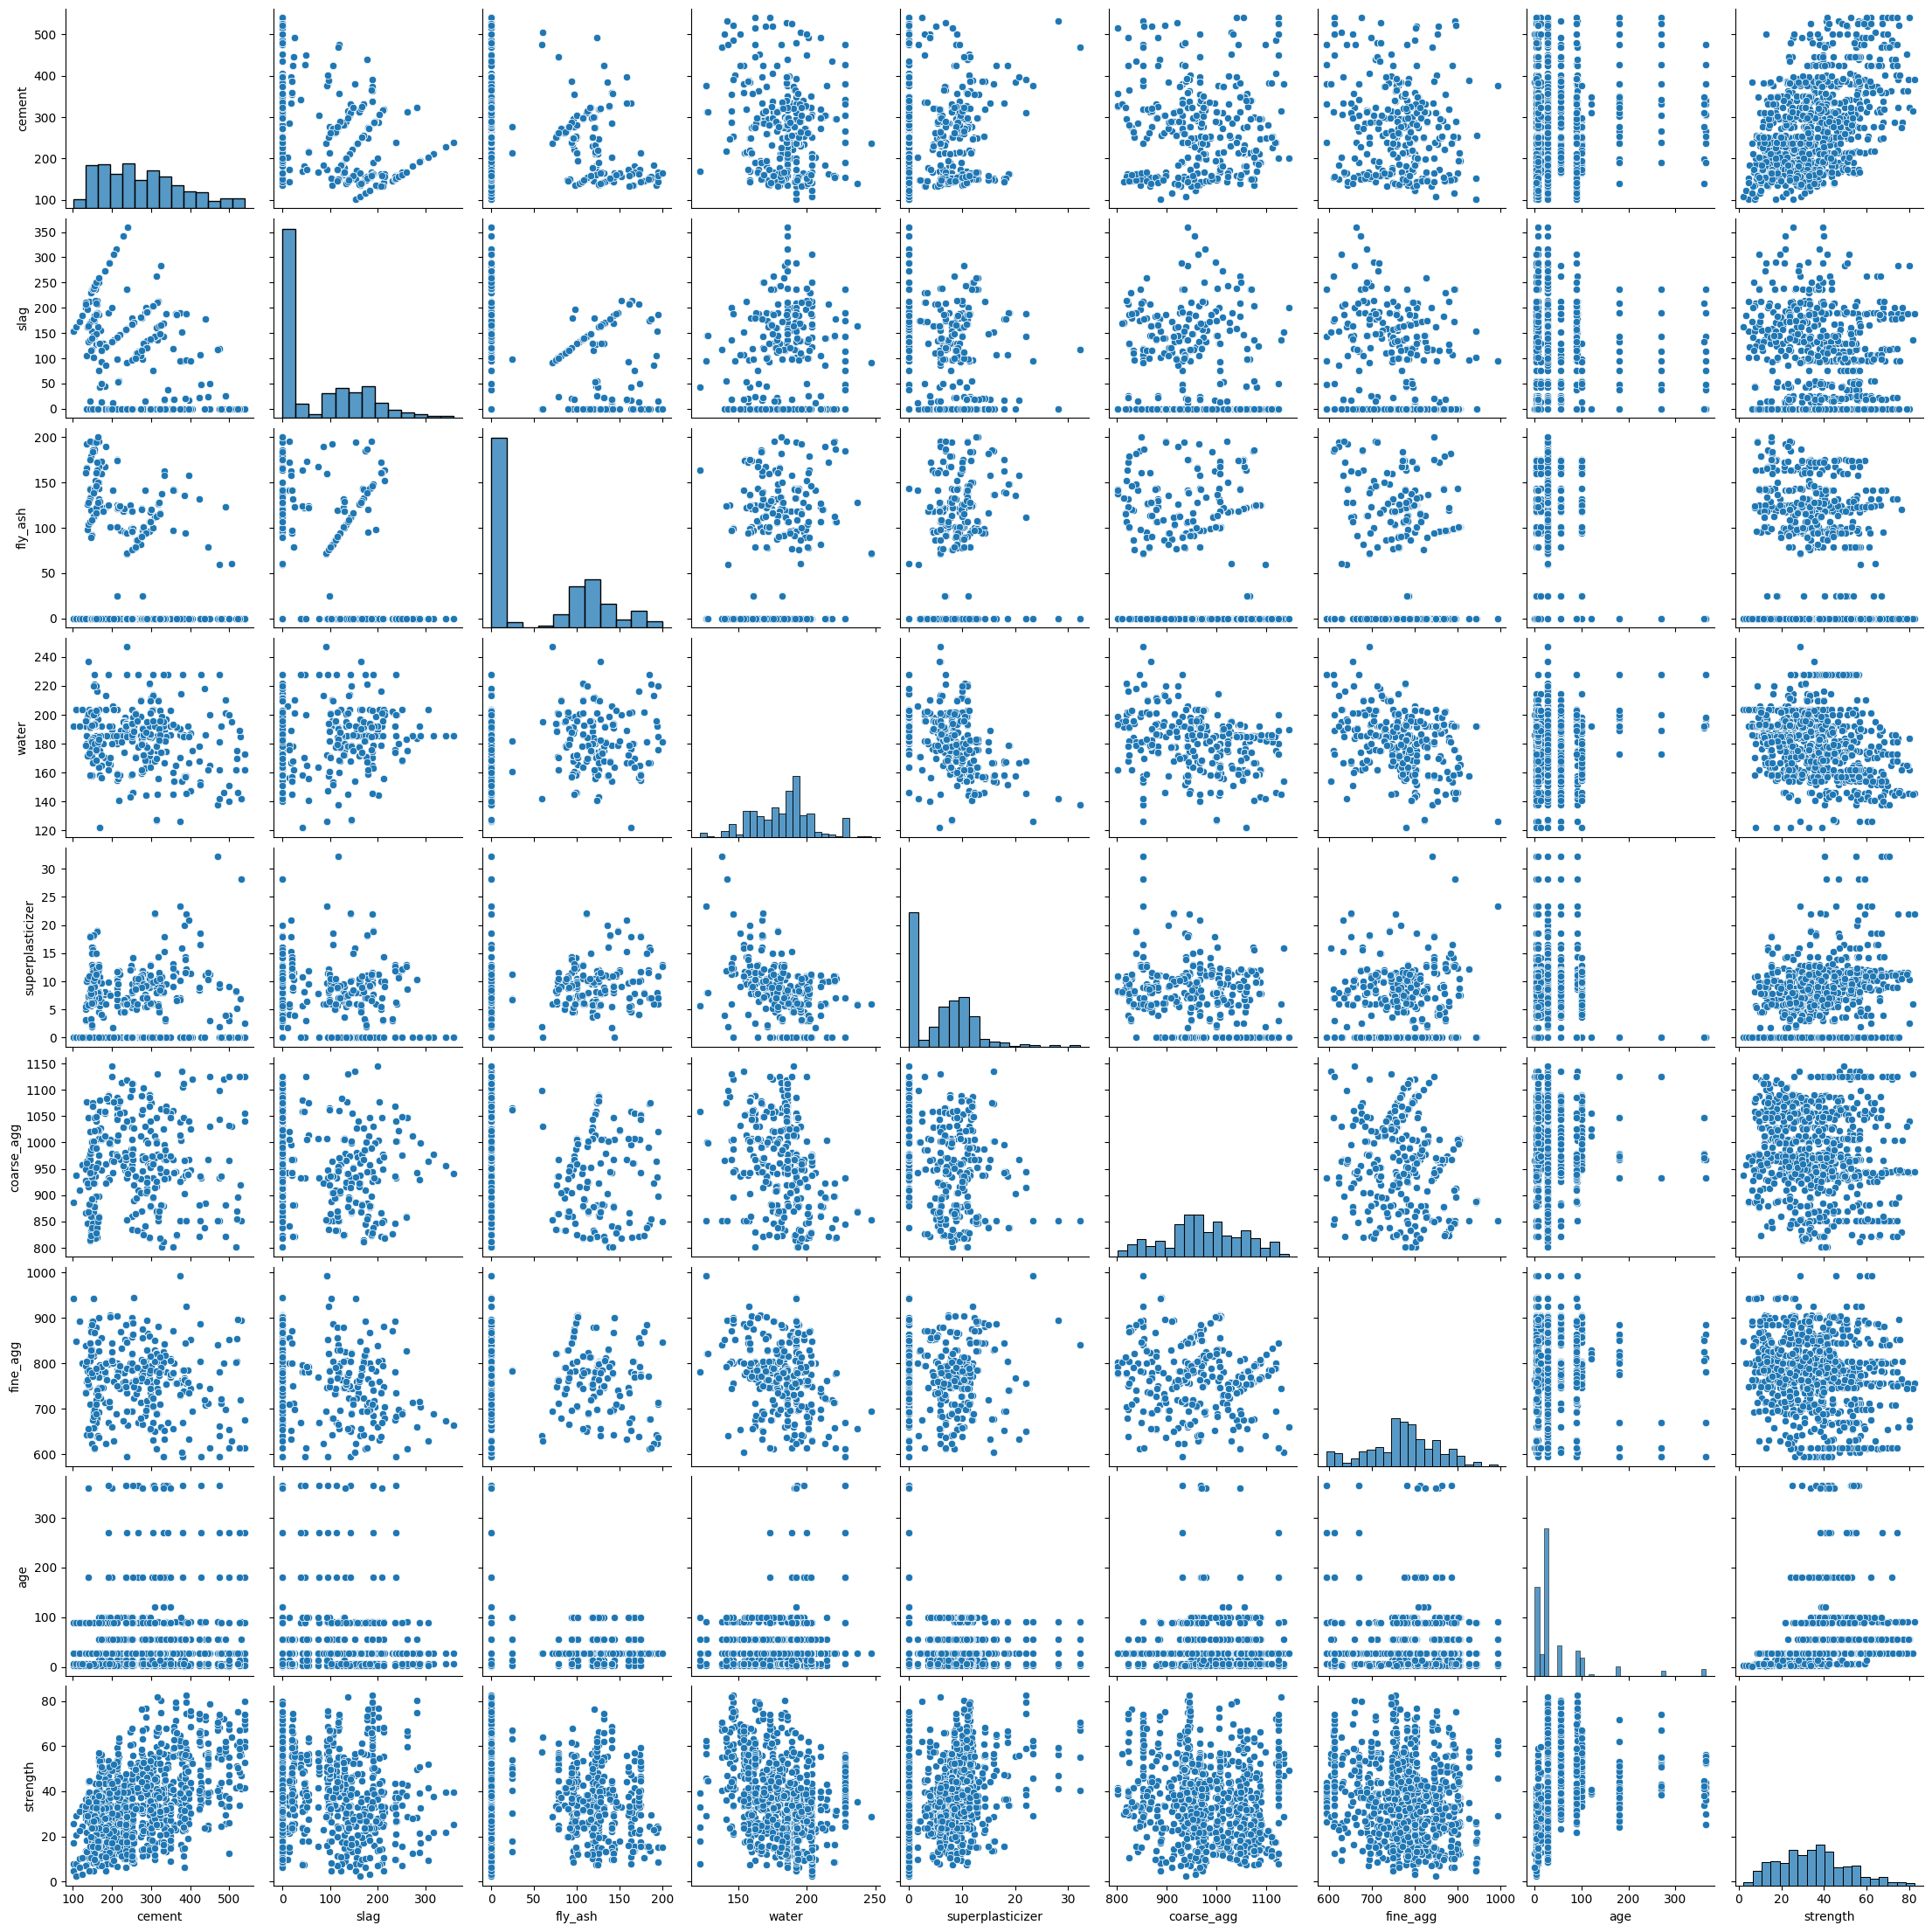

In [68]:
sns.pairplot(df)

Major Insights in correlation between features:
1. The highest correlation of 0.49 is between strength and cement.
2. The lowest correlation of -0.65 is between water and superplasticizer as more superplastisizer ensures that less water is needed to make the cement. As water should be reduced in the process of making cement, this relationship is highly beneficial.
3. The correlation of 0.41 between fly-ash and superplastisizer shows that both the quantities tend to increase together. Fly-ash having a correlation of -0.28 with water shows that it helps to reduce water content in cement.
4. Age and strength having correlation of 0.34 means increase in the time the cement is given to rest increases it's overall strngth.
5. Fine-aggregate and water have a correlation of -0.45 indicating that an increase in the amount of fine aggregate may be associated with a decrease in water content.
6. As no feature has correlation of more than 0.5 with strength, we can say that no single ingredient expalins the strength and strength is a culmination of all the ingredients.

## Splitting training and testing data:

In [69]:
from sklearn.model_selection import train_test_split

x = df.iloc[:,:-1]
y = df.iloc[:,-1]
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.25, random_state=42)

## Feature Engineering

In [70]:
x_test_norm=pd.DataFrame()
x_train_norm = pd.DataFrame()

from sklearn.preprocessing import FunctionTransformer

ft = FunctionTransformer(func = np.log1p)
for i in x_train.columns:
  ft.fit(x_train[i])
  x_train_norm[i] = ft.transform(x_train[i])

for i in x_test.columns:
  x_test_norm[i] = ft.transform(x_test[i])

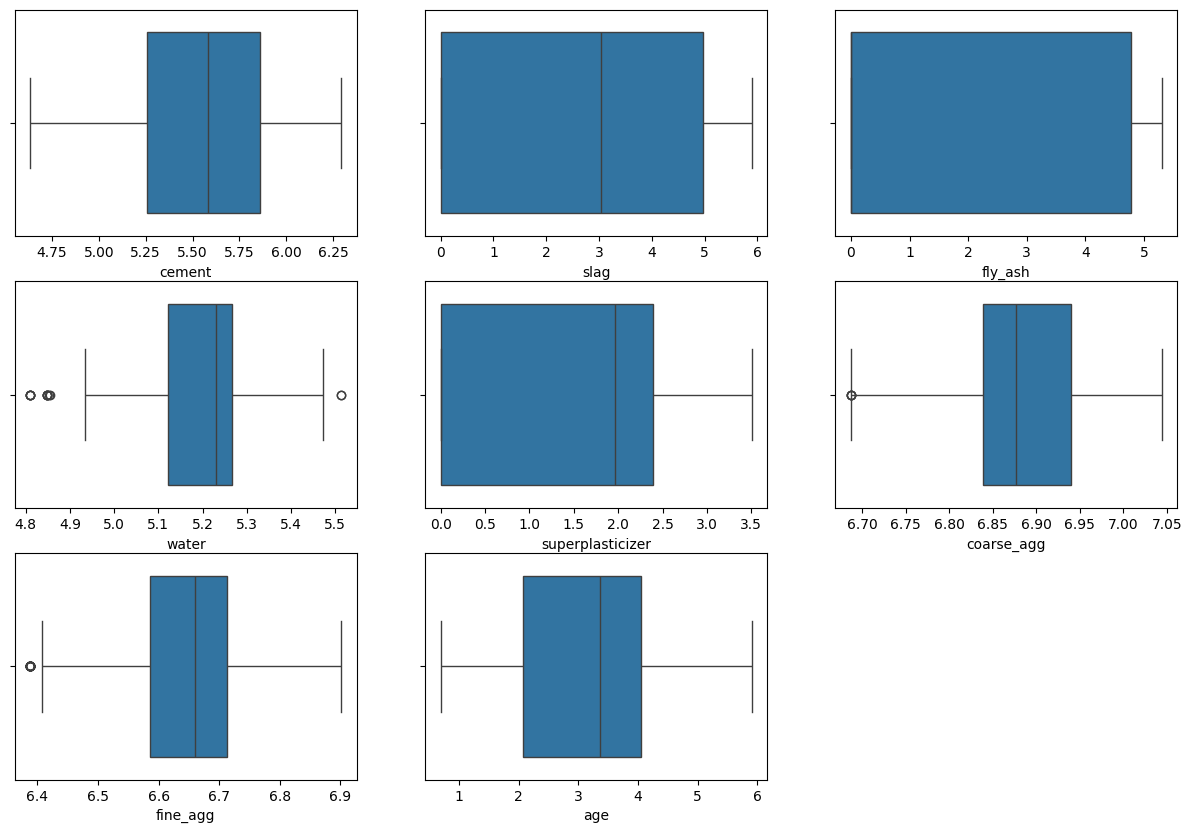

In [71]:
x_all = pd.concat([x_train_norm, x_test_norm])

plt.figure(figsize=(15,10))
plotnum = 1

for i in x_all.columns:
  if plotnum <= 9:
    ax = plt.subplot(3,3,plotnum)
    sns.boxplot(data=x_all, x=i, ax=ax)
  plotnum+=1

plt.savefig(f"{save_dir}/after_boxplot.png", dpi=150, bbox_inches="tight")
plt.show()

Outliers are taken care of after normalization.

## Scaling data

In [72]:
from sklearn.preprocessing import StandardScaler

ss = StandardScaler()
x_train_scale = ss.fit_transform(x_train_norm)
x_test_scale = ss.fit_transform(x_test_norm)

We are scaling the data for those models that need the data to be on the same level

### Cross validation data

In [73]:
from sklearn.model_selection import cross_val_score, KFold

cv = KFold(n_splits=5, random_state=42, shuffle=True)

## Training model

In [ ]:
retrain = False

In [79]:
FINAL_MODEL_PATH = os.path.join(save_dir, "final_model.pkl")
ALL_MODELS_PATH = os.path.join(save_dir, "all_models.csv")

if os.path.exists(FINAL_MODEL_PATH) and os.path.exists(ALL_MODELS_PATH) and not retrain:
  print("Saved models found, skipping training...(Saved time, yay capitalism!)")
  final_model = joblib.load(f"{save_dir}/final_model.pkl")
  all_models = pd.read_csv(f"{save_dir}/all_models.csv")
else:
  print("No saved models found. You now have an excuse to relax! Let the models train and let your managers know you indeed are working.")
  from sklearn.model_selection import RandomizedSearchCV
  from sklearn.linear_model import LinearRegression, Lasso
  from sklearn.tree import DecisionTreeRegressor
  from sklearn.neighbors import KNeighborsRegressor
  from sklearn.svm import SVR
  from sklearn.ensemble import VotingRegressor, RandomForestRegressor, GradientBoostingRegressor
  from xgboost import XGBRegressor
  from sklearn.model_selection import GridSearchCV

  metrics={
      "Lasso": (Lasso(max_iter=10000),{"alpha":[0.001, 0.01, 0.1, 1]}),
      "KNN": (KNeighborsRegressor(),{"n_neighbors": [3,5,7,9,12], "weights":["uniform", "distance"], "p":[1,2]}),
      "SVM": (SVR(),{"C": [1, 10, 100, 1000], "gamma": ["scale", 0.05, 0.1, 0.3, 1], "epsilon": [0.01, 0.1, 1]}),
      "Decision Tree": (DecisionTreeRegressor(random_state=42),{"max_depth": [3, 5, 7, 10, None], "min_samples_leaf": [1, 2, 5, 10]}),
      "Random Forest": (RandomForestRegressor(random_state=42),{"n_estimators": [200, 400], "max_depth": [None, 10, 20],
                        "min_samples_leaf": [1, 2, 4], "max_features": [1.0, 0.7, 0.5]}),
      "Gradient Boost": (GradientBoostingRegressor(random_state=42),
                        {"n_estimators": [200, 400], "learning_rate": [0.03, 0.05, 0.1],
                          "max_depth": [2, 3, 4, 5], "subsample": [0.7, 0.85, 1.0]}),
      "XG Boost": (XGBRegressor(random_state=42),
                  {"n_estimators": [200, 400, 600], "learning_rate": [0.03, 0.05, 0.1],
                    "max_depth": [3, 4, 5, 6, 7], "subsample": [0.7, 0.85, 1.0],
                    "colsample_bytree": [0.7, 0.85, 1.0]})
  }

  rows = []

  for name, (model,params) in metrics.items():
    s = RandomizedSearchCV(model, params, n_iter=20, cv=cv, scoring="r2", random_state=42, n_jobs=-1)
    s.fit(x_train_scale, y_train)
    rows.append([name, s.best_score_, s.best_params_])

  r2 = cross_val_score(LinearRegression(), x_train_scale, y_train, cv=cv, scoring="r2")
  rows.append(["Linear Regression", r2.mean(), "No parameters"])

  tuned = pd.DataFrame(rows, columns=["Model", "Best CV R2 Score", "Best params"]).sort_values("Best CV R2 Score", ascending=False).reset_index(drop=True)
  tuned

  best_score=[]
  best_models = {}
  top_models = [n for n in tuned["Model"]][:4]
  metrics_grid={n: metrics[n] for n in top_models}

  for name, (model,params) in metrics_grid.items():
    model_grid = GridSearchCV(model,params, cv=cv, scoring="r2", n_jobs=-1)
    model_grid.fit(x_train_scale, y_train)
    best_models[name] = model_grid.best_estimator_
    best_score.append([name, model_grid.best_score_, model_grid.best_params_])

  voting = VotingRegressor(estimators=list(best_models.items()),weights=[2, 2, 1, 1])
  v_r2 = cross_val_score(voting, x_train_scale, y_train, cv=cv, scoring="r2")
  voting.fit(x_train_scale, y_train)

  best_models["Voting Regression"] = voting
  best_score.append(["Voting Regression", v_r2.mean(), "tuned models averaged"])

  model_tune_grid = pd.DataFrame(best_score,columns=["Model", "Best CV R2 Score", "Best params"]).sort_values("Best CV R2 Score", ascending=False).reset_index(drop=True)
  model_tune_grid

  df_tune_trim = pd.DataFrame(tuned.iloc[4:])
  all_models = pd.concat([model_tune_grid, df_tune_trim], ignore_index=True)

  best = model_tune_grid.loc[0,"Model"]
  final_model = best_models[best]

  os.makedirs(save_dir, exist_ok=True)
  joblib.dump(final_model,f"{save_dir}/final_model.pkl",compress=3)
  all_models.to_csv(f"{save_dir}/all_models.csv", index=False)


Saved models found, skipping training...(Saved time, yay capitalism!)


## Best model

In [76]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
pred = final_model.predict(x_test_scale)
best = all_models.loc[0,"Model"]

print("Selected :", best)
print("Test R2  :", r2_score(y_test, pred))
print("Test RMSE:", mean_squared_error(y_test, pred) ** 0.5)
print("Test MAE :", mean_absolute_error(y_test, pred))

Selected : Voting Regression
Test R2  : 0.8788234350518355
Test RMSE: 5.924873245019753
Test MAE : 4.150972859323217


## Compairing Models

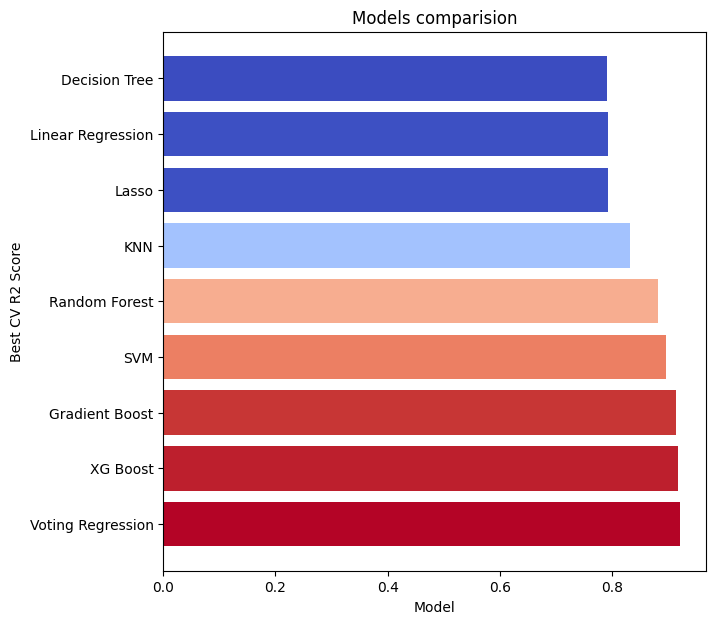

In [77]:
norm = plt.Normalize(all_models['Best CV R2 Score'].min(), all_models['Best CV R2 Score'].max())
colors = plt.cm.coolwarm(norm(all_models['Best CV R2 Score']))

plt.figure(figsize=(7,7))
plt.barh(all_models['Model'], all_models['Best CV R2 Score'], color=colors)
plt.xlabel("Model")
plt.ylabel("Best CV R2 Score")
plt.title("Models comparision")
plt.savefig(f"{save_dir}/model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

This graphs compares all the models which we have trained. They are coloured according to the R2 Score.

## Predicted vs Actual data for best model

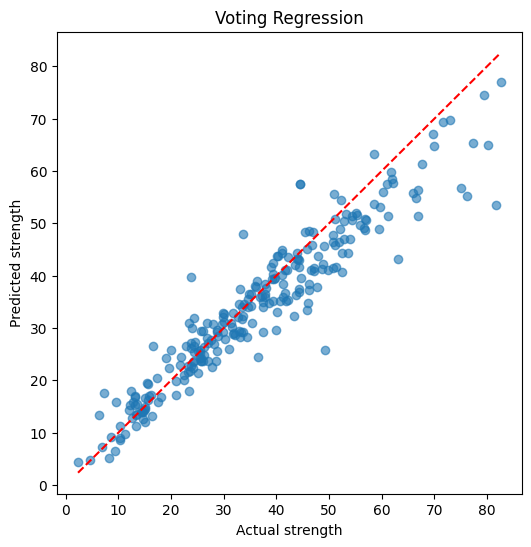

In [78]:
plt.figure(figsize=(6,6))
plt.scatter(y_test, pred, alpha=0.6)
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, "r--")
plt.xlabel("Actual strength")
plt.ylabel("Predicted strength")
plt.title("Voting Regression")
plt.savefig(f"{save_dir}/pred_vs_actual.png", dpi=150, bbox_inches="tight")
plt.show()

This graph shows the accuracy of the best model by evaluating the density of the points on the scatter plot and seeing how close they are to the central line, which has the formula $y = x$. This line represents 100% accuracy, meaning the closer the points are to the line, the more accurate the model is.